# AgroInvest
## 04 - Proyección de precios futuros

En este notebook se desarrolla un escenario económico adicional basado en la evolución histórica de los precios.

El objetivo es estimar valores futuros para las principales variables económicas utilizadas por AgroInvest:

- precio de venta por tonelada;
- precio del gasóleo;
- precio de fitosanitarios;
- precio de semillas;
- precio del fertilizante;
- gastos fijos por hectárea.

Dado que el histórico disponible contiene un número reducido de campañas, las proyecciones se interpretan como escenarios de tendencia y no como predicciones exactas de mercado.

Estas estimaciones se utilizarán posteriormente como parámetros económicos dentro del motor de recomendación de AgroInvest.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression

In [4]:
df_historicos = pd.read_excel(
    "Balance_economico_precios_distintos.xlsx"
)

df_historicos.columns = (
    df_historicos.columns
    .str.strip()
)

df_historicos["Cultivo"] = (
    df_historicos["Cultivo"]
    .astype(str)
    .str.strip()
)

df_historicos["Parcela"] = (
    df_historicos["Parcela"]
    .astype(str)
    .str.strip()
)

In [6]:
df_historicos.shape

(105, 36)

In [8]:
df_historicos["Precio_unitario_semilla"] = (
    df_historicos["Precio_Semillas_ha"]
    / df_historicos["Semillas_ha"]
)

In [10]:
#tabla anual de precios
variables_precios = [
    "Precio_tonelada_venta",
    "Precio_litro_gasoleoB",
    "Precio_litro_Fitosanitario",
    "Precio_unitario_semilla",
    "Precio_Abono_kg",
    "Gastos_fijos_por_ha"
]

In [12]:
precios_anuales = (
    df_historicos
    .groupby(["Cultivo", "Año"])[variables_precios]
    .mean()
    .reset_index()
)

precios_anuales.round(4)

,Cultivo,Año,Precio_tonelada_venta,Precio_litro_gasoleoB,Precio_litro_Fitosanitario,Precio_unitario_semilla,Precio_Abono_kg,Gastos_fijos_por_ha
0,Arroz,2020,320.0,0.6010,86.0,18.1000,0.38,420.00
1,Arroz,2021,330.0,0.7101,89.0,21.2000,0.42,480.00
2,Arroz,2023,550.0,0.7704,94.0,20.2000,0.65,530.00
3,Arroz,2024,440.0,1.0247,100.0,19.0000,0.50,550.00
4,Arroz,2025,280.0,0.9621,103.0,18.9000,0.48,570.00
5,Arroz,2026,300.0,1.2701,108.0,18.0000,0.53,590.00
6,Maiz,2020,220.0,0.6010,63.0,0.0030,0.42,669.50
7,Maiz,2021,260.0,0.7101,72.0,0.0031,0.50,709.50
8,Maiz,2023,290.0,0.7704,70.0,0.0034,0.70,789.50
9,Maiz,2024,252.0,1.0247,72.0,0.0037,0.57,809.50


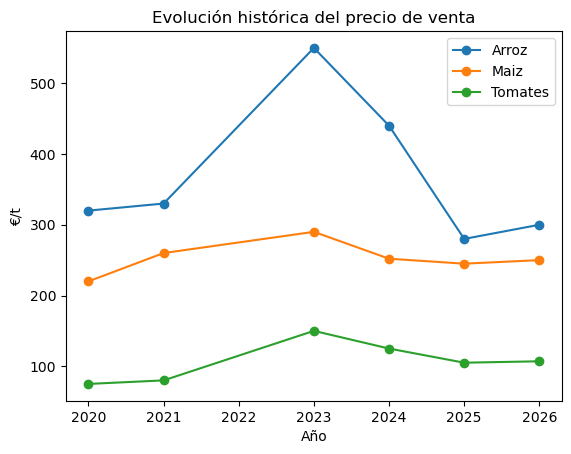

In [14]:
#evolucion histórica
for cultivo in precios_anuales["Cultivo"].unique():

    datos = precios_anuales[
        precios_anuales["Cultivo"] == cultivo
    ]

    plt.plot(
        datos["Año"],
        datos["Precio_tonelada_venta"],
        marker="o",
        label=cultivo
    )

plt.title("Evolución histórica del precio de venta")
plt.xlabel("Año")
plt.ylabel("€/t")
plt.legend()
plt.show()

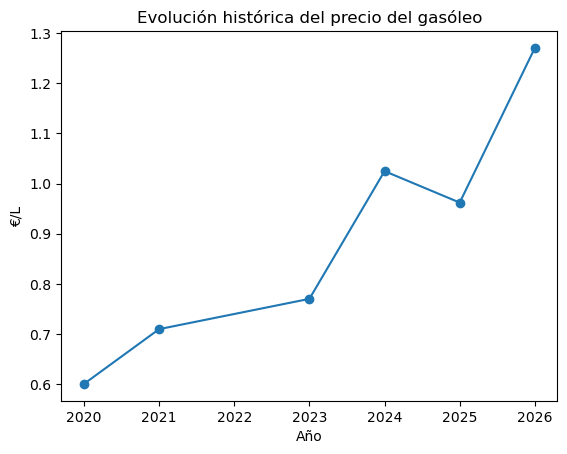

In [16]:
gasoleo_anual = (
    df_historicos
    .groupby("Año")["Precio_litro_gasoleoB"]
    .mean()
)

gasoleo_anual.plot(
    marker="o"
)

plt.title("Evolución histórica del precio del gasóleo")
plt.xlabel("Año")
plt.ylabel("€/L")
plt.show()

In [18]:
#regresión lineal
def proyectar_variable(
    df,
    cultivo,
    variable,
    anio_objetivo
):

    datos = (
        df[df["Cultivo"] == cultivo]
        .groupby("Año")[variable]
        .mean()
        .reset_index()
    )

    X = datos[["Año"]]
    y = datos[variable]

    modelo = LinearRegression()

    modelo.fit(
        X,
        y
    )

    prediccion = modelo.predict(
        pd.DataFrame(
            {"Año": [anio_objetivo]}
        )
    )[0]

    return prediccion

In [20]:
precio_maiz_2028 = proyectar_variable(
    df=df_historicos,
    cultivo="Maiz",
    variable="Precio_tonelada_venta",
    anio_objetivo=2028
)

precio_maiz_2028

263.49068322981293

In [22]:
precio_gasoil_2028 = proyectar_variable(
    df=df_historicos,
    cultivo="Maiz",
    variable="Precio_litro_gasoleoB",
    anio_objetivo=2028
)

precio_gasoil_2028

1.3663900621118046

In [24]:
def proyectar_parametros_economicos(
    df,
    cultivo,
    anio_objetivo
):

    parametros = {}

    for variable in variables_precios:

        parametros[variable] = (
            proyectar_variable(
                df=df,
                cultivo=cultivo,
                variable=variable,
                anio_objetivo=anio_objetivo
            )
        )

    return parametros

In [26]:
parametros_maiz_2028 = (
    proyectar_parametros_economicos(
        df=df_historicos,
        cultivo="Maiz",
        anio_objetivo=2028
    )
)

parametros_maiz_2028

{'Precio_tonelada_venta': 263.49068322981293,
 'Precio_litro_gasoleoB': 1.3663900621118046,
 'Precio_litro_Fitosanitario': 80.41614906832274,
 'Precio_unitario_semilla': 0.004137813664596257,
 'Precio_Abono_kg': 0.7163354037267098,
 'Gastos_fijos_por_ha': 936.2080745341518}

In [28]:
pd.DataFrame(
    parametros_maiz_2028.items(),
    columns=[
        "Variable",
        "Prediccion_2028"
    ]
).round(4)

,Variable,Prediccion_2028
0,Precio_tonelada_venta,263.4907
1,Precio_litro_gasoleoB,1.3664
2,Precio_litro_Fitosanitario,80.4161
3,Precio_unitario_semilla,0.0041
4,Precio_Abono_kg,0.7163
5,Gastos_fijos_por_ha,936.2081


In [30]:
def evaluar_tendencia_variable(
    df,
    cultivo,
    variable
):

    datos = (
        df[df["Cultivo"] == cultivo]
        .groupby("Año")[variable]
        .mean()
        .reset_index()
    )

    X = datos[["Año"]]
    y = datos[variable]

    modelo = LinearRegression()
    modelo.fit(X, y)

    r2 = modelo.score(X, y)

    return r2

In [32]:
evaluacion_tendencias = []

for variable in variables_precios:

    r2 = evaluar_tendencia_variable(
        df=df_historicos,
        cultivo="Maiz",
        variable=variable
    )

    evaluacion_tendencias.append({
        "Variable": variable,
        "R2_tendencia": r2
    })

pd.DataFrame(
    evaluacion_tendencias
).round(3)

,Variable,R2_tendencia
0,Precio_tonelada_venta,0.051
1,Precio_litro_gasoleoB,0.876
2,Precio_litro_Fitosanitario,0.739
3,Precio_unitario_semilla,0.969
4,Precio_Abono_kg,0.511
5,Gastos_fijos_por_ha,0.986


## Estrategia de proyección de precios

El análisis de las tendencias históricas muestra que no todas las variables económicas presentan una evolución temporal suficientemente estable como para ser proyectadas mediante una regresión lineal.

Por este motivo se utiliza una estrategia híbrida:

- variables con una tendencia histórica clara (`R² ≥ 0,70`) se proyectan mediante regresión lineal;
- variables con una tendencia moderada (`0,40 ≤ R² < 0,70`) utilizan una tendencia suavizada;
- variables con escasa relación temporal (`R² < 0,40`) se estiman mediante la media de los últimos años disponibles.

Este enfoque evita extrapolar de forma excesiva variables especialmente volátiles, como el precio de venta de los cultivos.

In [35]:
def proyectar_variable_hibrida(
    df,
    cultivo,
    variable,
    anio_objetivo,
    n_ultimos=3
):

    datos = (
        df[df["Cultivo"] == cultivo]
        .groupby("Año")[variable]
        .mean()
        .reset_index()
        .sort_values("Año")
    )

    X = datos[["Año"]]
    y = datos[variable]

    modelo = LinearRegression()
    modelo.fit(X, y)

    r2 = modelo.score(X, y)

    prediccion_lineal = modelo.predict(
        pd.DataFrame(
            {"Año": [anio_objetivo]}
        )
    )[0]

    # Tendencia clara
    if r2 >= 0.70:

        prediccion = prediccion_lineal
        metodo = "Tendencia lineal"

    # Tendencia moderada:
    # combinamos tendencia y media reciente
    elif r2 >= 0.40:

        media_reciente = (
            datos.tail(n_ultimos)[variable]
            .mean()
        )

        prediccion = (
            0.5 * prediccion_lineal
            + 0.5 * media_reciente
        )

        metodo = "Tendencia suavizada"

    # Sin tendencia clara
    else:

        prediccion = (
            datos.tail(n_ultimos)[variable]
            .mean()
        )

        metodo = "Media últimos años"

    return {
        "Prediccion": prediccion,
        "R2": r2,
        "Metodo": metodo
    }

In [37]:
proyeccion_precio_maiz = proyectar_variable_hibrida(
    df=df_historicos,
    cultivo="Maiz",
    variable="Precio_tonelada_venta",
    anio_objetivo=2028
)

proyeccion_precio_maiz

{'Prediccion': 249.0,
 'R2': 0.05054982080434833,
 'Metodo': 'Media últimos años'}

In [39]:
def proyectar_parametros_hibridos(
    df,
    cultivo,
    anio_objetivo
):

    resultados = {}

    for variable in variables_precios:

        resultados[variable] = (
            proyectar_variable_hibrida(
                df=df,
                cultivo=cultivo,
                variable=variable,
                anio_objetivo=anio_objetivo
            )
        )

    return resultados

In [41]:
proyecciones_maiz_2028 = proyectar_parametros_hibridos(
    df=df_historicos,
    cultivo="Maiz",
    anio_objetivo=2028
)

proyecciones_maiz_2028

{'Precio_tonelada_venta': {'Prediccion': 249.0,
  'R2': 0.05054982080434833,
  'Metodo': 'Media últimos años'},
 'Precio_litro_gasoleoB': {'Prediccion': 1.3663900621118046,
  'R2': 0.8757209756844415,
  'Metodo': 'Tendencia lineal'},
 'Precio_litro_Fitosanitario': {'Prediccion': 80.41614906832274,
  'R2': 0.7393818995649617,
  'Metodo': 'Tendencia lineal'},
 'Precio_unitario_semilla': {'Prediccion': 0.004137813664596257,
  'R2': 0.9689321701383387,
  'Metodo': 'Tendencia lineal'},
 'Precio_Abono_kg': {'Prediccion': 0.6565010351966882,
  'R2': 0.5105245580021978,
  'Metodo': 'Tendencia suavizada'},
 'Gastos_fijos_por_ha': {'Prediccion': 936.2080745341518,
  'R2': 0.9862745949702562,
  'Metodo': 'Tendencia lineal'}}

In [43]:
tabla_proyeccion_2028 = pd.DataFrame([
    {
        "Variable": variable,
        "Prediccion": resultado["Prediccion"],
        "R2": resultado["R2"],
        "Metodo": resultado["Metodo"]
    }
    for variable, resultado
    in proyecciones_maiz_2028.items()
])

tabla_proyeccion_2028.round(4)

,Variable,Prediccion,R2,Metodo
0,Precio_tonelada_venta,249.0000,0.0505,Media últimos años
1,Precio_litro_gasoleoB,1.3664,0.8757,Tendencia lineal
2,Precio_litro_Fitosanitario,80.4161,0.7394,Tendencia lineal
3,Precio_unitario_semilla,0.0041,0.9689,Tendencia lineal
4,Precio_Abono_kg,0.6565,0.5105,Tendencia suavizada
5,Gastos_fijos_por_ha,936.2081,0.9863,Tendencia lineal


## Escenarios futuros

Debido a la incertidumbre asociada a la evolución de los mercados agrícolas, la proyección futura no se representa mediante una única estimación.

A partir del escenario central obtenido mediante el modelo híbrido de tendencias se construyen tres escenarios:

- **Conservador:** contempla condiciones económicas menos favorables para la explotación, con menores precios de venta y mayores costes de producción.
- **Central:** utiliza directamente las estimaciones obtenidas mediante el modelo híbrido de proyección.
- **Alcista:** contempla condiciones económicas más favorables, con mayores precios de venta y menores costes de producción.

Estos escenarios permiten evaluar la sensibilidad de las inversiones tecnológicas ante distintas condiciones futuras de mercado.

In [48]:
parametros_centrales_2028 = {
    variable: resultado["Prediccion"]
    for variable, resultado
    in proyecciones_maiz_2028.items()
}

parametros_centrales_2028

{'Precio_tonelada_venta': 249.0,
 'Precio_litro_gasoleoB': 1.3663900621118046,
 'Precio_litro_Fitosanitario': 80.41614906832274,
 'Precio_unitario_semilla': 0.004137813664596257,
 'Precio_Abono_kg': 0.6565010351966882,
 'Gastos_fijos_por_ha': 936.2080745341518}

In [50]:
def crear_escenarios_futuros(
    parametros_centrales,
    variacion=0.10
):

    escenario_central = (
        parametros_centrales.copy()
    )

    escenario_conservador = (
        parametros_centrales.copy()
    )

    escenario_alcista = (
        parametros_centrales.copy()
    )

    # --------------------------------
    # Precio de venta
    # --------------------------------

    escenario_conservador[
        "Precio_tonelada_venta"
    ] *= (1 - variacion)

    escenario_alcista[
        "Precio_tonelada_venta"
    ] *= (1 + variacion)

    # --------------------------------
    # Costes de producción
    # --------------------------------

    variables_coste = [
        "Precio_litro_gasoleoB",
        "Precio_litro_Fitosanitario",
        "Precio_unitario_semilla",
        "Precio_Abono_kg",
        "Gastos_fijos_por_ha"
    ]

    for variable in variables_coste:

        # Conservador:
        # costes más elevados
        escenario_conservador[
            variable
        ] *= (1 + variacion)

        # Alcista:
        # costes más bajos
        escenario_alcista[
            variable
        ] *= (1 - variacion)

    return {
        "Conservador": escenario_conservador,
        "Central": escenario_central,
        "Alcista": escenario_alcista
    }

In [52]:
escenarios_2028 = crear_escenarios_futuros(
    parametros_centrales_2028,
    variacion=0.10
)

In [54]:
tabla_escenarios_2028 = pd.DataFrame(
    escenarios_2028
).T

tabla_escenarios_2028.round(4)

,Precio_tonelada_venta,Precio_litro_gasoleoB,Precio_litro_Fitosanitario,Precio_unitario_semilla,Precio_Abono_kg,Gastos_fijos_por_ha
Conservador,224.1,1.5030,88.4578,0.0046,0.7222,1029.8289
Central,249.0,1.3664,80.4161,0.0041,0.6565,936.2081
Alcista,273.9,1.2298,72.3745,0.0037,0.5909,842.5873


In [71]:
def obtener_descuento_humedad_medio(
    df,
    cultivo
):
    
    valores = df[
        df["Cultivo"] == cultivo
    ]["Descuento_humedad_por_t"]

    if valores.notna().sum() == 0:
        return np.nan

    return valores.mean()

In [73]:
print(
    "Maiz:",
    obtener_descuento_humedad_medio(
        df_historicos,
        "Maiz"
    )
)

print(
    "Arroz:",
    obtener_descuento_humedad_medio(
        df_historicos,
        "Arroz"
    )
)

print(
    "Tomates:",
    obtener_descuento_humedad_medio(
        df_historicos,
        "Tomates"
    )
)

Maiz: -20.465235294117647
Arroz: -25.68895238095238
Tomates: nan


In [75]:
def generar_escenarios_futuros_cultivo(
    df,
    cultivo,
    anio_objetivo,
    variacion=0.10
):

    # -----------------------------------
    # Proyección central
    # -----------------------------------

    proyecciones = proyectar_parametros_hibridos(
        df=df,
        cultivo=cultivo,
        anio_objetivo=anio_objetivo
    )

    parametros_centrales = {
        variable: resultado["Prediccion"]
        for variable, resultado
        in proyecciones.items()
    }

    # -----------------------------------
    # Crear escenarios
    # -----------------------------------

    escenarios = crear_escenarios_futuros(
        parametros_centrales,
        variacion=variacion
    )

    # -----------------------------------
    # Añadir descuento por humedad
    # -----------------------------------

    descuento_humedad = (
        obtener_descuento_humedad_medio(
            df,
            cultivo
        )
    )

    for escenario in escenarios.values():

        escenario[
            "Descuento_humedad_por_t"
        ] = descuento_humedad

    return escenarios

In [77]:
escenarios_maiz_2028 = (
    generar_escenarios_futuros_cultivo(
        df=df_historicos,
        cultivo="Maiz",
        anio_objetivo=2028,
        variacion=0.10
    )
)

In [79]:
pd.DataFrame(
    escenarios_maiz_2028
).T.round(4)

,Precio_tonelada_venta,Precio_litro_gasoleoB,Precio_litro_Fitosanitario,Precio_unitario_semilla,Precio_Abono_kg,Gastos_fijos_por_ha,Descuento_humedad_por_t
Conservador,224.1,1.5030,88.4578,0.0046,0.7222,1029.8289,-20.4652
Central,249.0,1.3664,80.4161,0.0041,0.6565,936.2081,-20.4652
Alcista,273.9,1.2298,72.3745,0.0037,0.5909,842.5873,-20.4652


In [81]:
escenarios_arroz_2028 = (
    generar_escenarios_futuros_cultivo(
        df=df_historicos,
        cultivo="Arroz",
        anio_objetivo=2028,
        variacion=0.10
    )
)

In [83]:
pd.DataFrame(
    escenarios_arroz_2028
).T.round(4)

,Precio_tonelada_venta,Precio_litro_gasoleoB,Precio_litro_Fitosanitario,Precio_unitario_semilla,Precio_Abono_kg,Gastos_fijos_por_ha,Descuento_humedad_por_t
Conservador,306.0,1.5030,125.6186,20.4967,0.5537,717.6646,-25.689
Central,340.0,1.3664,114.1988,18.6333,0.5033,652.4224,-25.689
Alcista,374.0,1.2298,102.7789,16.7700,0.4530,587.1801,-25.689


In [85]:
escenarios_tomates_2028 = (
    generar_escenarios_futuros_cultivo(
        df=df_historicos,
        cultivo="Tomates",
        anio_objetivo=2028,
        variacion=0.10
    )
)

In [87]:
pd.DataFrame(
    escenarios_tomates_2028
).T.round(4)

,Precio_tonelada_venta,Precio_litro_gasoleoB,Precio_litro_Fitosanitario,Precio_unitario_semilla,Precio_Abono_kg,Gastos_fijos_por_ha,Descuento_humedad_por_t
Conservador,101.1000,1.5030,154.5124,0.0743,0.7187,2591.3227,NaN
Central,112.3333,1.3664,140.4658,0.0676,0.6533,2355.7480,NaN
Alcista,123.5667,1.2298,126.4193,0.0608,0.5880,2120.1732,NaN


In [89]:
def generar_escenarios_todos_cultivos(
    df,
    anio_objetivo,
    variacion=0.10
):

    cultivos = [
        "Maiz",
        "Arroz",
        "Tomates"
    ]

    escenarios_por_cultivo = {}

    for cultivo in cultivos:

        escenarios_por_cultivo[cultivo] = (
            generar_escenarios_futuros_cultivo(
                df=df,
                cultivo=cultivo,
                anio_objetivo=anio_objetivo,
                variacion=variacion
            )
        )

    return escenarios_por_cultivo

In [91]:
escenarios_futuros_2028 = (
    generar_escenarios_todos_cultivos(
        df=df_historicos,
        anio_objetivo=2028,
        variacion=0.10
    )
)

In [93]:
escenarios_futuros_2028.keys()

dict_keys(['Maiz', 'Arroz', 'Tomates'])

In [95]:
escenarios_futuros_2028["Arroz"]["Central"]

{'Precio_tonelada_venta': 340.0,
 'Precio_litro_gasoleoB': 1.3663900621118046,
 'Precio_litro_Fitosanitario': 114.19875776397475,
 'Precio_unitario_semilla': 18.633333333333333,
 'Precio_Abono_kg': 0.5033333333333333,
 'Gastos_fijos_por_ha': 652.4223602484417,
 'Descuento_humedad_por_t': -25.68895238095238}

In [97]:
escenarios_futuros_2028["Arroz"]["Central"]

{'Precio_tonelada_venta': 340.0,
 'Precio_litro_gasoleoB': 1.3663900621118046,
 'Precio_litro_Fitosanitario': 114.19875776397475,
 'Precio_unitario_semilla': 18.633333333333333,
 'Precio_Abono_kg': 0.5033333333333333,
 'Gastos_fijos_por_ha': 652.4223602484417,
 'Descuento_humedad_por_t': -25.68895238095238}

## Conclusión

En este notebook se ha desarrollado el escenario de proyección futura de AgroInvest.

A partir de los precios históricos se analiza individualmente la tendencia de cada variable económica. Las variables con una tendencia temporal clara se proyectan mediante regresión lineal, mientras que aquellas con menor estabilidad utilizan métodos más conservadores basados en tendencias suavizadas o medias recientes.

Sobre la proyección central se generan tres escenarios económicos futuros:

- conservador;
- central;
- alcista.

Estos escenarios modifican de forma coherente los precios de venta y los costes de producción, permitiendo analizar cómo podría variar la rentabilidad de una inversión tecnológica bajo diferentes condiciones futuras de mercado.

La proyección debe interpretarse como un escenario orientativo basado en tendencias históricas y no como una predicción garantizada de los precios futuros.

Los escenarios generados quedan preparados para integrarse posteriormente con el motor técnico y financiero de AgroInvest.